# Step 01. Cubic Spline 경로 생성

> **author**: Minwon Lee
> **참고**: PythonRobotics (https://github.com/AtsushiSakai/PythonRobotics) — original author Atsushi Sakai (@Atsushi_twi) / License MIT 코드 참고
>
> **교육 주관**: Hanyang University, Automotive Intelligence Laboratory (AILAB)

전역 경로는 띄엄띄엄한 점들로 주어짐. 이 점들을 차가 따라갈 수 있는 부드러운 곡선으로 잇는 방법을 3차 스플라인(cubic spline)으로 살펴봄.

## 학습 목표

1. 점을 직선으로 이을 때 생기는 방향 꺾임(불연속) 확인
2. 각 구간을 3차함수 $a + b\Delta + c\Delta^2 + d\Delta^3$ 로 표현
3. 구간 접점의 부드러움(C0 / C1 / C2 연속) 조건 이해
4. 라이브러리가 푼 계수로 각 구간 3차함수 값을 직접 계산 → C0 (TODO)
5. 기울기(1차 미분)를 직접 계산해 접점에서 기울기 연속 확인 → C1 (TODO)
6. 구간별 3차함수를 이어 만든 cubic spline 시각화
7. 점 이동에 따른 spline 변화 관찰 (interactive)

In [1]:
%matplotlib inline
import sys, os, math
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../utils/02_trajectory_planning'))

import numpy as np
import matplotlib.pyplot as plt

from utils.cubic_spline import CubicSpline1D
from step01_cubic_spline_path import (
    plot_straight_line_limit,
    plot_segment_definition,
    plot_slope_comparison,
    plot_cubic_spline,
    interactive_spline,
)

print('ready')

ready


## 1. 직선 연결의 한계

점들을 직선으로 이으면 코너(빨간 점)마다 방향이 꺾임. 오른쪽 그래프의 방향각(heading)은 구간 안에서는 일정하다가 코너에서 불연속으로 점프. 차가 따라가려면 그 점에서 방향을 급히 바꿔야 하므로 부드러운 곡선이 필요.

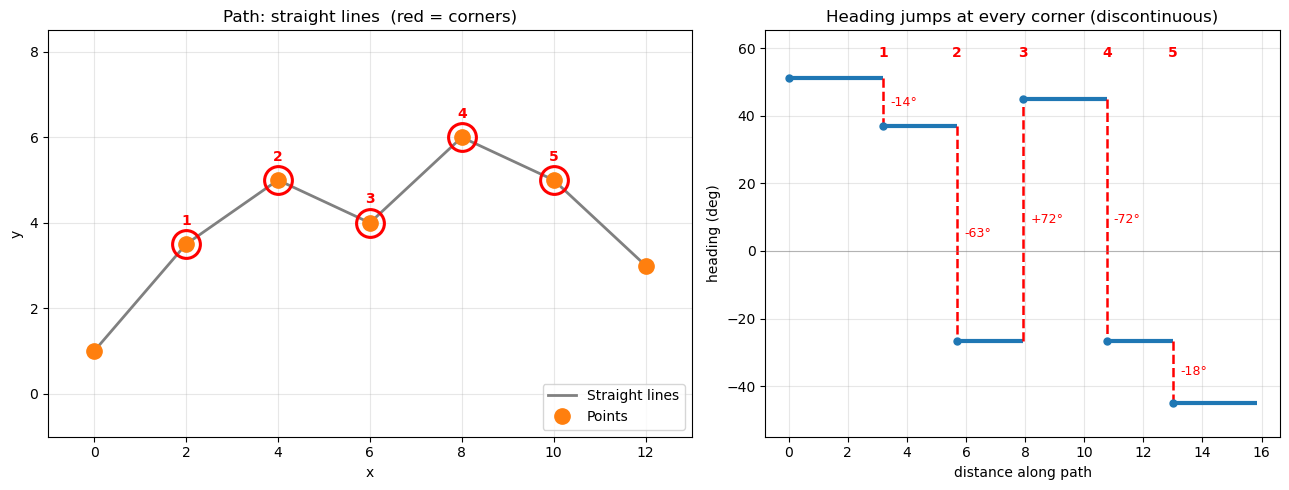

In [2]:
# 전역 경로 점 7개
x = [0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0]
y = [1.0, 3.5, 5.0, 4.0, 6.0,  5.0,  3.0]

plot_straight_line_limit(x, y)

## 2. 구간별 3차함수 표현

이웃한 두 점 사이(한 구간)를 3차함수 하나로 표현. 시작점 $x_i$ 기준 거리를 $\Delta = x - x_i$ 로 두면

$$S_i(\Delta) = a_i + b_i\,\Delta + c_i\,\Delta^2 + d_i\,\Delta^3$$

구간마다 계수 네 개 $a, b, c, d$ 로 곡선 한 조각 결정. 점 7개 → 구간 6개 → 계수 $6 \times 4 = 24$ 개.

아래 그림으로 구조 확인. 왼쪽은 색이 다른 각 조각(3차함수 $S_0, S_1, \dots$), 오른쪽은 이음매 $x_1$ 에서 맞춰야 할 연속 조건.

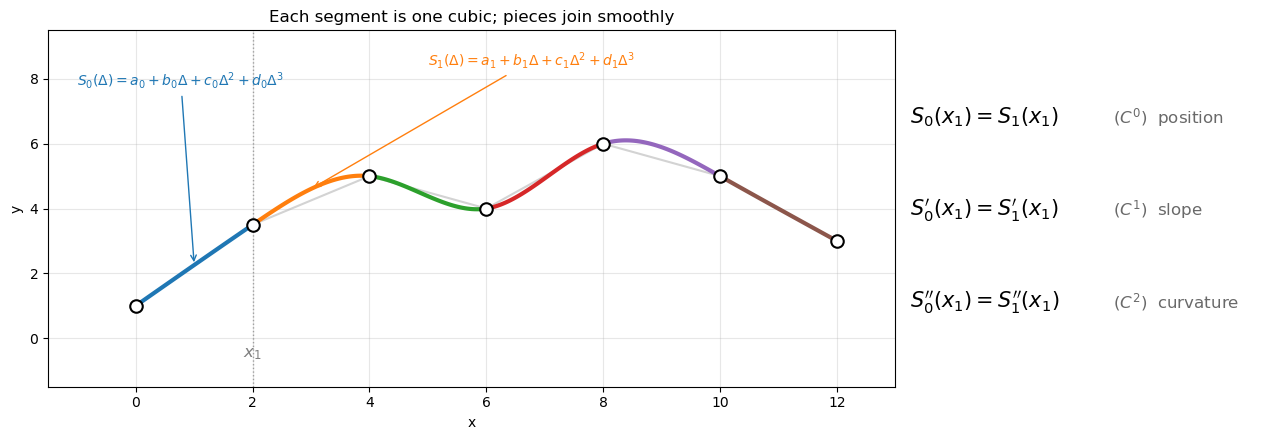

In [3]:
plot_segment_definition(x, y)

## 3. 부드러움 조건 (C0 / C1 / C2)

계수 24개를 정하려면 그만큼의 조건이 필요. 접점(구간과 구간이 만나는 점)에서 세 가지 연속을 요구.

1. 함숫값 연속 (C0): 두 조각의 끝 높이가 같음 → 경로가 끊기지 않음
2. 1차 미분(기울기) 연속 (C1): 들어오는 기울기 = 나가는 기울기 → 방향이 안 꺾임
3. 2차 미분(곡률) 연속 (C2): 휘는 정도가 같음 → 곡률이 안 튐(승차감)

이 조건 + 양 끝 경계조건 → 계수 24개 결정. 계수 푸는 과정은 라이브러리에 위임.

## 4. [TODO] 3차함수 조각 직접 계산

구간 $i$ 는 시작점 $x_i$ 로부터의 거리 $\Delta = x - x_i$ 에 대해

$$S_i(\Delta) = a_i + b_i\,\Delta + c_i\,\Delta^2 + d_i\,\Delta^3$$

계수 $a, b, c, d$ 는 라이브러리(`CubicSpline1D`)가 푼 값 사용. 위 공식 한 줄을 코드로 옮기는 작업.

아래 `evaluate_cubic_segment` 의 TODO 한 줄 작성 → 이 함수가 5·6번 그림을 직접 구동.

In [8]:
def evaluate_cubic_segment(a, b, c, d, delta):
    ##### TODO #####
    # 3차함수 조각 값 계산
    #   S(delta) = a + b*delta + c*delta**2 + d*delta**3
    #################

    position = a + b * delta + c * delta ** 2 + d * delta ** 3

    #################
    return position

print('evaluate_cubic_segment defined')

evaluate_cubic_segment defined


In [9]:
sp = CubicSpline1D(x, y)

# 구간별 계수 (라이브러리)
print('seg |     a       b       c       d')
print('----+--------------------------------')
for i in range(len(x) - 1):
    print(f' S{i} | {sp.a[i]:7.3f} {sp.b[i]:7.3f} {sp.c[i]:7.3f} {sp.d[i]:7.3f}')

# 라이브러리 결과(calc_position)와 비교
max_error = 0.0
for i in range(len(x) - 1):
    for query_x in np.linspace(x[i], x[i + 1], 50):
        mine      = evaluate_cubic_segment(sp.a[i], sp.b[i], sp.c[i], sp.d[i], query_x - x[i])
        reference = sp.calc_position(query_x)
        max_error = max(max_error, abs(mine - reference))

print(f'\nmax error vs library = {max_error:.2e}')
assert max_error < 1e-12, 'TODO 공식이 라이브러리와 불일치'
print('OK: 3차함수 계산이 라이브러리와 일치')

seg |     a       b       c       d
----+--------------------------------
 S0 |   1.000   1.258   0.000  -0.002
 S1 |   3.500   1.233  -0.013  -0.115
 S2 |   5.000  -0.192  -0.700   0.273
 S3 |   4.000   0.283   0.938  -0.290
 S4 |   6.000   0.558  -0.800   0.135
 S5 |   5.000  -1.017   0.012  -0.002

max error vs library = 4.44e-16
OK: 3차함수 계산이 라이브러리와 일치


## 5. [TODO] 기울기(방향) 직접 계산

부드러움의 핵심은 접점에서 기울기 연속(C1). 3차함수 $S_i(\Delta) = a + b\Delta + c\Delta^2 + d\Delta^3$ 를 $\Delta$ 로 한 번 미분하면

$$S_i'(\Delta) = b_i + 2c_i\,\Delta + 3d_i\,\Delta^2$$

아래 TODO 한 줄 작성 후 경로를 따라 기울기 변화 확인. 직선(기울기 점프)과 비교.

In [10]:
def evaluate_cubic_slope(a, b, c, d, delta):
    ##### TODO #####
    # 기울기(1차 미분) 계산
    #   S'(delta) = b + 2*c*delta + 3*d*delta**2
    #################

    slope = b + 2 * c * delta + 3 * d * delta ** 2

    #################
    return slope

# 라이브러리 결과(calc_first_derivative)와 비교
sp = CubicSpline1D(x, y)
max_error = 0.0
for i in range(len(x) - 1):
    for query_x in np.linspace(x[i], x[i + 1], 50):
        mine      = evaluate_cubic_slope(sp.a[i], sp.b[i], sp.c[i], sp.d[i], query_x - x[i])
        reference = sp.calc_first_derivative(query_x)
        max_error = max(max_error, abs(mine - reference))
print(f'max error vs library = {max_error:.2e}')
assert max_error < 1e-12, 'TODO 공식이 라이브러리와 불일치'
print('OK: 기울기 계산이 라이브러리와 일치')

max error vs library = 6.66e-16
OK: 기울기 계산이 라이브러리와 일치


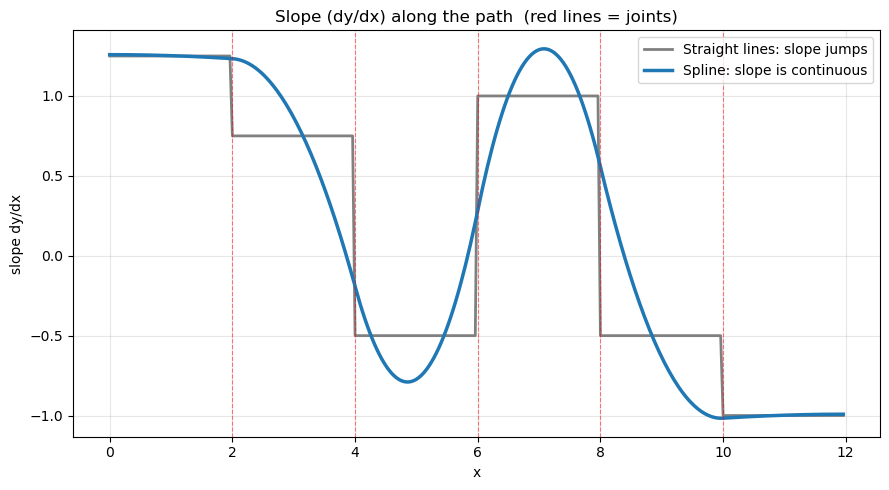

In [11]:
plot_slope_comparison(x, y, evaluate_cubic_slope)

## 6. Cubic Spline 시각화

값(4번)·기울기(5번)가 접점에서 매끄럽게 이어짐을 확인 → 완성된 곡선 확인. `evaluate_cubic_segment` 로 각 구간 조각을 조각별 색으로 표시. 색이 바뀌는 곳이 접점이며, 직선과 달리 매끄럽게 연결.

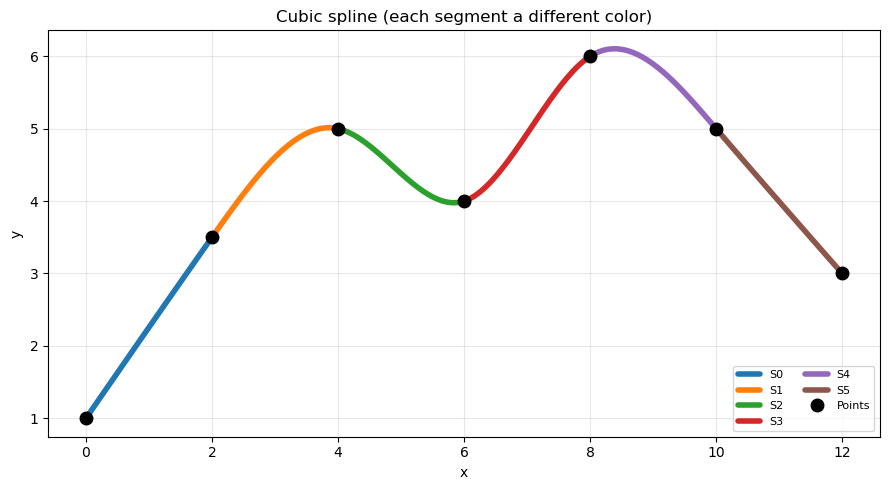

In [12]:
plot_cubic_spline(x, y, evaluate_cubic_segment)

## 7. 점 이동에 따른 spline 변화 (interactive)

점 하나를 위아래로 움직이면 그 점을 지나도록 spline 재생성. 슬라이더로 점 번호와 높이 y 조절. (JupyterLab / Notebook 에서 실시간 동작, 정적 미리보기에서는 한 장면만 표시.)

In [13]:
interactive_spline(x, y, evaluate_cubic_segment)

interactive(children=(IntSlider(value=3, description='point', max=5, min=1), FloatSlider(value=4.0, descriptio…

<function step01_cubic_spline_path.interactive_spline.<locals>.show_spline(point=3, y_value=4.0)>